# EDA 


## Import

In [12]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import re

try:
    from IPython.display import HTML, display
except ImportError:

    def display(obj):
        print(obj)

    HTML = None


# Remove gridlines/borders from pandas HTML tables in-notebook
if HTML is not None:
    display(
        HTML(
            """
<style>
table.dataframe { border: none !important; border-collapse: collapse !important; }
table.dataframe thead th, table.dataframe tbody th, table.dataframe tbody td { border: none !important; }
</style>
"""
        )
    )


_here = Path(".").resolve()
if (_here / "dataset.csv").exists():
    ROOT = _here
elif (_here / "42850A2" / "dataset.csv").exists():
    ROOT = _here / "42850A2"
else:
    ROOT = _here
DATA_PATH = ROOT / "dataset.csv"
FIG_DIR = ROOT / "eda_figures"
FIG_DIR.mkdir(exist_ok=True)


sns.set_theme(
    style="white",
    context="talk",
    palette="colorblind",
    rc={"axes.grid": False},
)
plt.rcParams.update(
    {
        "figure.facecolor": "white",
        "axes.titlesize": 14,
        "axes.labelsize": 12,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "legend.fontsize": 11,
        "figure.dpi": 120,
        "savefig.dpi": 300,
        "savefig.bbox": "tight",
        "axes.grid": False,
    }
)

LABEL_COLS = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate",
]

## Data Loading

In [13]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH} (cd into 42850A2 or upload dataset.csv on Colab)"
    )

df = pd.read_csv(DATA_PATH)
text_col = "comment_text"


if "is_harmful" not in df.columns:
    df["is_harmful"] = (df[LABEL_COLS].sum(axis=1) > 0).astype(int)

df[text_col] = df[text_col].astype(str)

print("rows:", len(df), "cols:", list(df.columns))
print("missing comment_text:", df[text_col].isna().sum())
print("duplicate ids:", df["id"].duplicated().sum())

# Consistency: is_harmful vs. union of six toxicity columns
computed = (df[LABEL_COLS].sum(axis=1) > 0).astype(int)
mismatch = (computed != df["is_harmful"]).sum()
print("is_harmful vs sum(labels): mismatches:", int(mismatch))

df.head(2)

rows: 20000 cols: ['id', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate', 'is_harmful']
missing comment_text: 0
duplicate ids: 0
is_harmful vs sum(labels): mismatches: 0


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,is_harmful
0,80857fbe9a005d0f,File:IMG 0037.JPG.JPG listed for deletion \nA ...,0,0,0,0,0,0,0
1,eb1c20e7b8e268c7,Moslims are filthy thugs who do not belong on ...,1,0,1,0,1,1,1


## Text Length

In [14]:
s = df[text_col].fillna("")
df["char_len"] = s.str.len()
df["word_len"] = s.str.split().str.len()

try:
    from IPython.display import display
except ImportError:

    def display(obj):  
        print(obj)


bin_tbl = pd.DataFrame(
    {
        "count": df["is_harmful"].value_counts().sort_index(),
        "percent": (df["is_harmful"].value_counts(normalize=True).sort_index() * 100).round(2),
    }
)
bin_tbl.index = bin_tbl.index.map(lambda i: f"is_harmful={int(i)}")
display(bin_tbl)

summary_tbl = pd.DataFrame(
    {
        "positive_rate_pct": (df[LABEL_COLS].mean() * 100).round(3),
        "positive_count": df[LABEL_COLS].sum(),
    }
)
display(summary_tbl.sort_values("positive_rate_pct"))

q = df[["char_len", "word_len"]].quantile([0.5, 0.9, 0.95, 0.99]).round(1)
display(q)

print("Figures saved to:", FIG_DIR.resolve())

,count,percent
is_harmful,,
is_harmful=0,10000,50.0
is_harmful=1,10000,50.0


,positive_rate_pct,positive_count
threat,1.555,311
identity_hate,4.460,892
severe_toxic,4.975,995
insult,24.070,4814
obscene,25.940,5188
toxic,47.105,9421


,char_len,word_len
0.50,166.0,29.0
0.90,749.0,129.0
0.95,1224.0,208.0
0.99,3761.0,599.0


Figures saved to: D:\UTS\26S1\42850\assessment\a3\42850A2\eda_figures


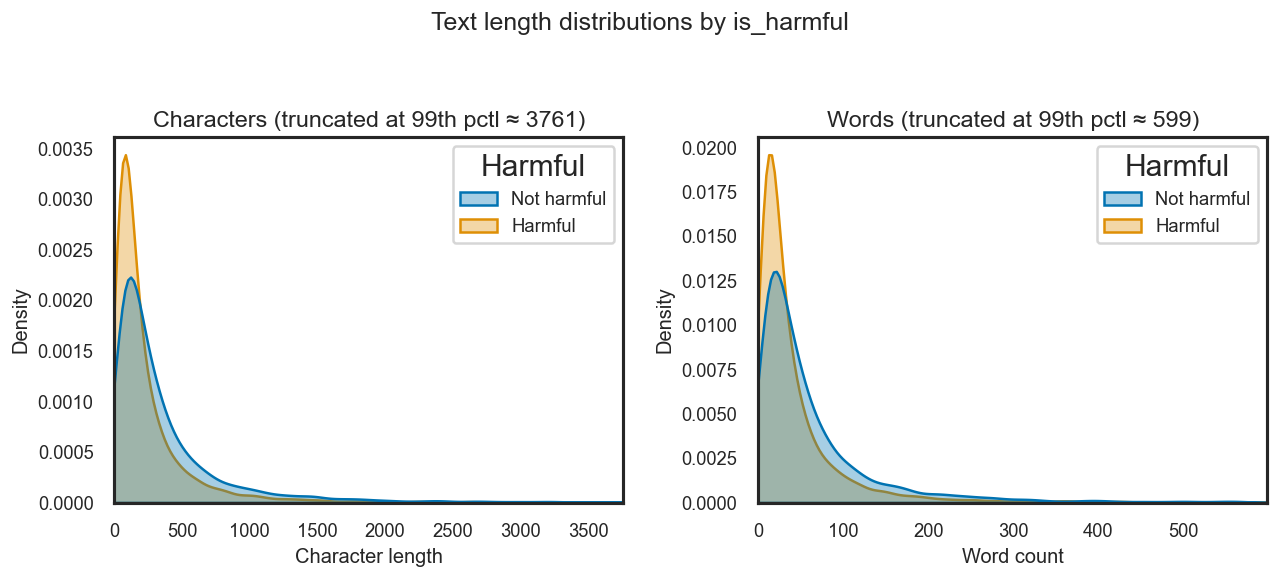

C:\Users\Yvett\AppData\Local\Temp\ipykernel_30876\3132631379.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=plot_df[plot_df["word_len"] <= cap_word], x="Harmful", y="word_len", palette=["#6baed6", "#fb6a4a"], ax=ax, inner="box")


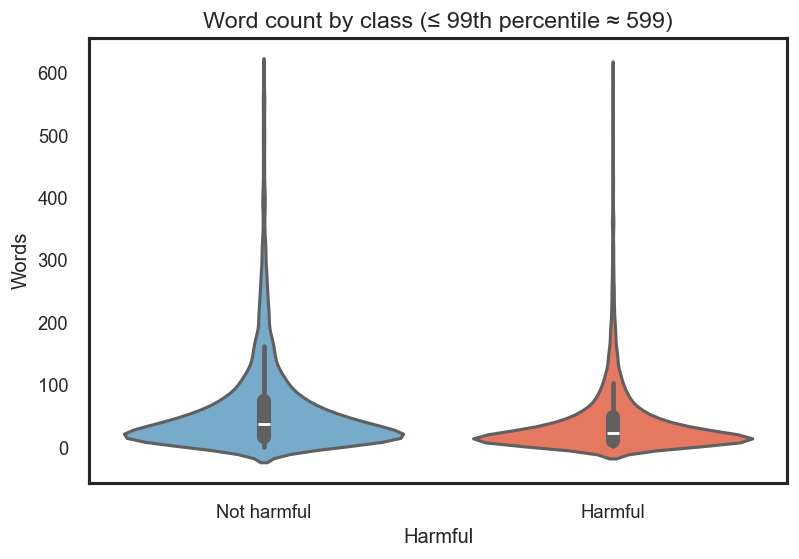

In [15]:
cap_char = df["char_len"].quantile(0.99)
cap_word = df["word_len"].quantile(0.99)

plot_df = df[["char_len", "word_len", "is_harmful"]].copy()
plot_df["Harmful"] = plot_df["is_harmful"].map({0: "Not harmful", 1: "Harmful"})

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
sns.kdeplot(data=plot_df[plot_df["char_len"] <= cap_char], x="char_len", hue="Harmful", common_norm=False, ax=axes[0], fill=True, alpha=0.35)
axes[0].set_xlim(0, cap_char)
axes[0].set_xlabel("Character length")
axes[0].set_title(f"Characters (truncated at 99th pctl ≈ {cap_char:.0f})")

sns.kdeplot(data=plot_df[plot_df["word_len"] <= cap_word], x="word_len", hue="Harmful", common_norm=False, ax=axes[1], fill=True, alpha=0.35)
axes[1].set_xlim(0, cap_word)
axes[1].set_xlabel("Word count")
axes[1].set_title(f"Words (truncated at 99th pctl ≈ {cap_word:.0f})")
fig.suptitle("Text length distributions by is_harmful", y=1.02, fontsize=15)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_length_kde_by_harmful.png")
plt.show()

fig2, ax = plt.subplots(figsize=(7, 5))
sns.violinplot(data=plot_df[plot_df["word_len"] <= cap_word], x="Harmful", y="word_len", palette=["#6baed6", "#fb6a4a"], ax=ax, inner="box")
ax.set_title(f"Word count by class (≤ 99th percentile ≈ {cap_word:.0f})")
ax.set_ylabel("Words")
fig2.tight_layout()
fig2.savefig(FIG_DIR / "06_wordlen_violin.png")
plt.show()

## Text Pattern Analysis

In [ ]:
REPEAT_CHAR_RE = re.compile(r"(.)\1{2,}")
REPEAT_PUNCT_RE = re.compile(r"[!?]{2,}")
TOKEN_RE = re.compile(r"\S+")

s_orig = s.fillna("").astype(str).str.strip('"')

tokens_per_doc = s_orig.map(lambda t: TOKEN_RE.findall(t))

DOC_ALLCAPS_WORD_RE = re.compile(r"\b[A-Z]{3,}\b")
doc_tbl = pd.DataFrame(
    {
        "has_allcaps_word": s_orig.str.contains(DOC_ALLCAPS_WORD_RE),
        "has_repeat_punct": s_orig.str.contains(REPEAT_PUNCT_RE),
        "has_repeat_char": s_orig.str.contains(REPEAT_CHAR_RE),
        "n_exclam": s_orig.str.count("!"),
        "n_qmark": s_orig.str.count("\\?"),
    }
)


doc_flag_tbl = (
    doc_tbl.join(df[["is_harmful"]])
    .groupby("is_harmful")
    .agg(
        allcaps_word_pct=("has_allcaps_word", lambda x: round(float(x.mean() * 100), 2)),
        repeat_punct_pct=("has_repeat_punct", lambda x: round(float(x.mean() * 100), 2)),
        repeat_char_pct=("has_repeat_char", lambda x: round(float(x.mean() * 100), 2)),
        avg_exclam=("n_exclam", lambda x: round(float(x.mean()), 3)),
        avg_qmark=("n_qmark", lambda x: round(float(x.mean()), 3)),
    )
    .rename(index={0: "is_harmful=0", 1: "is_harmful=1"})
)
doc_flag_tbl


max_docs_for_tokens = 20000
if len(df) > max_docs_for_tokens:
    sample_idx = df.sample(max_docs_for_tokens, random_state=42).index
else:
    sample_idx = df.index

tok_df = (
    pd.DataFrame({"is_harmful": df.loc[sample_idx, "is_harmful"], "tokens": tokens_per_doc.loc[sample_idx]})
    .explode("tokens")
    .dropna()
    .rename(columns={"tokens": "tok"})
)


_tok = tok_df["tok"].astype(str)
tok_df["len"] = _tok.str.len()
tok_df["is_allcaps"] = _tok.str.fullmatch(r"[A-Z]{3,}").fillna(False)
tok_df["has_digit"] = _tok.str.contains(r"\d", regex=True)
tok_df["has_non_alnum"] = _tok.str.contains(r"[^A-Za-z0-9]", regex=True)
tok_df["has_repeat_char"] = _tok.str.contains(REPEAT_CHAR_RE)
tok_df["has_repeat_punct"] = _tok.str.contains(REPEAT_PUNCT_RE)


tok_summary = (
    tok_df.groupby("is_harmful")[
        ["is_allcaps", "has_digit", "has_non_alnum", "has_repeat_char", "has_repeat_punct"]
    ]
    .mean()
    .mul(100)
    .round(3)
    .rename(index={0: "is_harmful=0", 1: "is_harmful=1"})
)
tok_summary


long_tokens = (
    tok_df[tok_df["len"] >= 20]
    .groupby("tok")
    .size()
    .sort_values(ascending=False)
    .head(25)
    .rename("count")
    .reset_index()
)
long_tokens


allcaps_top = (
    tok_df[tok_df["is_allcaps"]]
    .groupby("tok")
    .size()
    .sort_values(ascending=False)
    .head(25)
    .rename("count")
    .reset_index()
)
allcaps_top


obfus_top = (
    tok_df[tok_df["has_digit"] | tok_df["has_non_alnum"]]
    .groupby("tok")
    .size()
    .sort_values(ascending=False)
    .head(25)
    .rename("count")
    .reset_index()
)
obfus_top

NameError: name 's_raw' is not defined

## Word Cloud

In [ ]:


try:
    from wordcloud import STOPWORDS, WordCloud
except ImportError as e:
    raise ImportError("Install wordcloud: pip install wordcloud") from e

WC_MAX_DOCS_PER_CLASS = 4000
WC_MAX_WORDS = 200

CONTRACTIONS = {
    "won't": "will not",
    "can't": "cannot",
    "n't": " not",
    "'re": " are",
    "'s": " is",
    "'d": " would",
    "'ll": " will",
    "'ve": " have",
    "'m": " am",
}


def preprocess_for_wordcloud(txt: str) -> str:
    t = str(txt).strip('"').lower()

    # Drop high-variance patterns
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)
    t = re.sub(r"\b[\w.+-]+@[\w-]+\.[\w.-]+\b", " ", t)
    t = re.sub(r"(?<!\w)@\w+", " ", t)
    t = re.sub(r"\b\d{1,3}(?:\.\d{1,3}){3}\b", " ", t)
    t = re.sub(r"<[^>]+>", " ", t)

    # Expand contractions (align with toxic_binary_nlp.ipynb intent)
    for contr, full in CONTRACTIONS.items():
        t = t.replace(contr, full)

    # Keep only letters/spaces for wordcloud
    t = re.sub(r"[^a-z\s]", " ", t)
    t = re.sub(r"\s+", " ", t).strip()
    return t


def build_corpus(mask: pd.Series) -> str:
    s = df.loc[mask, text_col].astype(str).map(preprocess_for_wordcloud)
    s = s[s.str.len() > 0]
    if len(s) > WC_MAX_DOCS_PER_CLASS:
        s = s.sample(WC_MAX_DOCS_PER_CLASS, random_state=42)
    return " ".join(s.tolist())


text_neg = build_corpus(df["is_harmful"] == 0)
text_pos = build_corpus(df["is_harmful"] == 1)

extra_stop = {
    "wikipedia",
    "wiki",
    "http",
    "https",
    "com",
    "org",
    "image",
    "file",
    "article",
    "page",
}
stop = set(STOPWORDS) | extra_stop

wc_kw = dict(
    width=900,
    height=520,
    background_color="white",
    max_words=WC_MAX_WORDS,
    stopwords=stop,
    relative_scaling=0.5,
    min_font_size=8,
    collocations=False,
)

wc0 = WordCloud(**wc_kw, colormap="Blues_r").generate(text_neg or "empty")
wc1 = WordCloud(**wc_kw, colormap="OrRd").generate(text_pos or "empty")

fig, axes = plt.subplots(1, 2, figsize=(16, 7.2))
axes[0].imshow(wc0, interpolation="bilinear")
axes[0].axis("off")
axes[0].set_title("Not harmful (is_harmful = 0)", fontsize=14, pad=10)
axes[1].imshow(wc1, interpolation="bilinear")
axes[1].axis("off")
axes[1].set_title("Harmful (is_harmful = 1)", fontsize=14, pad=10)
fig.suptitle("Word clouds for binary classes", fontsize=15, y=1.01)
fig.tight_layout()
fig.savefig(FIG_DIR / "08_binary_wordclouds.png")
plt.show()

wc0.to_file(FIG_DIR / "08a_wordcloud_not_harmful.png")
wc1.to_file(FIG_DIR / "08b_wordcloud_harmful.png")
print("Saved word clouds to", FIG_DIR)

ImportError: Install wordcloud: pip install wordcloud